# Germany power market: local EDA execution

Executed locally on 2026-11-09 using the original SMARD CSV exports. The analytical cells match the Fabric notebook source. These outputs do not represent a Fabric run.


In [1]:
from pathlib import Path
import pandas as pd

def load_hourly(root):
    raw = root / "data" / "raw" / "smard"
    timeline = pd.date_range("2025-01-01", "2026-01-01", freq="h", tz="Europe/Berlin", inclusive="left")
    frame = pd.DataFrame({
        "interval_start_utc": timeline.tz_convert("UTC"),
        "local_date": timeline.tz_localize(None).normalize(),
        "local_hour": timeline.hour,
    })
    frame["time_key"] = frame.interval_start_utc.dt.strftime("%Y%m%d%H").astype("int64")

    def source(category):
        path = raw / f"{category}_202501010000_202601010000_Hour.csv"
        result = pd.read_csv(path, sep=";", thousands=",", na_values="-")
        labels = pd.to_datetime(result["Start date"], format="%b %d, %Y %I:%M %p")
        assert labels.tolist() == timeline.tz_localize(None).tolist(), f"Invalid time sequence: {category}"
        return result

    consumption = source("Actual_consumption")
    generation = source("Actual_generation")
    price = source("Day-ahead_prices")
    frame["grid_load_mwh"] = consumption["grid load [MWh] Calculated resolutions"]
    frame["residual_load_mwh"] = consumption["Residual load [MWh] Calculated resolutions"]
    frame["day_ahead_price_eur_mwh"] = price["Germany/Luxembourg [€/MWh] Calculated resolutions"]
    for name, label in {"wind_onshore": "Wind onshore", "wind_offshore": "Wind offshore", "solar": "Photovoltaics"}.items():
        frame[f"{name}_mwh"] = generation[f"{label} [MWh] Calculated resolutions"]
    renewables = ["Biomass", "Hydropower", "Wind onshore", "Wind offshore", "Photovoltaics", "Other renewable"]
    renewable_columns = [f"{name} [MWh] Calculated resolutions" for name in renewables]
    assert generation[renewable_columns].notna().all().all(), "Missing renewable observations"
    assert generation["Nuclear [MWh] Calculated resolutions"].isna().all(), "Unexpected nuclear observations"
    frame["renewable_generation_mwh"] = generation[renewable_columns].sum(axis=1, min_count=len(renewables))
    frame["reported_generation_mwh"] = generation.iloc[:, 2:].sum(axis=1, min_count=1)
    return frame


def load_generation_mix(root):
    path = root / "data/raw/smard/Actual_generation_202501010000_202601010000_Hour.csv"
    generation = pd.read_csv(path, sep=";", thousands=",", na_values="-")
    codes = {
        "Biomass": "biomass", "Hydropower": "hydropower", "Wind offshore": "wind_offshore",
        "Wind onshore": "wind_onshore", "Photovoltaics": "solar", "Other renewable": "other_renewable",
        "Nuclear": "nuclear", "Lignite": "lignite", "Hard coal": "hard_coal", "Fossil gas": "fossil_gas",
        "Hydro pumped storage": "pumped_storage", "Other conventional": "other_conventional",
    }
    return pd.DataFrame([
        {"generation_source_code": code, "matched_hours": len(generation),
         "valid_hours": int(generation[f"{label} [MWh] Calculated resolutions"].count()),
         "generation_twh": generation[f"{label} [MWh] Calculated resolutions"].sum(min_count=1) / 1e6}
        for label, code in codes.items()
    ])

root = Path.cwd()
if not (root / 'data/raw/smard').exists():
    root = root.parent
eda_hourly = load_hourly(root)
eda_generation_mix = load_generation_mix(root)


## Renewable generation, price exposure and market regimes

The hourly research panel pairs German grid load and generation with the DE-LU day-ahead price. Generation is aggregated before joins, and every input must retain its declared grain. All quantities are hourly MWh; 1,000 MWh in an hour corresponds to 1 GW of average power.

Capture price is `sum(price * generation) / sum(generation)` over matched valid hours. Capture rate divides that price by the time-average market price over the same period; it is undefined when the benchmark is non-positive. Exposure products use hourly averages and are not realized revenue, curtailment losses or settlement values.

Negative-price exposure is the share of a source's generation occurring in hours whose exported hourly price is below zero. The hourly export cannot recover the number of negative quarter-hours after the October 2025 market-resolution change.


## Coverage and annual reference values

Reported generation sums available source categories. Nuclear remains unavailable rather than being treated as an observed zero. Renewable share uses reported generation, including pumped-storage output in its denominator; it is distinct from wind-and-solar generation divided by grid load.


In [2]:
# EDA_ANALYSIS: preparation and price reference.
import numpy as np
import pandas as pd

price_column = "day_ahead_price_eur_mwh"
metric_columns = [column for column in eda_hourly if column.endswith("_mwh")]
for column in metric_columns:
    eda_hourly[column] = pd.to_numeric(eda_hourly[column], errors="raise").astype(float)
eda_hourly["interval_start_utc"] = pd.to_datetime(eda_hourly["interval_start_utc"], utc=True)
eda_hourly["local_date"] = pd.to_datetime(eda_hourly["local_date"])
eda_hourly = eda_hourly.sort_values("time_key").reset_index(drop=True)
assert len(eda_hourly) == 8760 and eda_hourly.time_key.is_unique, "Unexpected hourly panel grain"
assert eda_hourly[metric_columns].notna().all().all(), "Missing research inputs"
assert (eda_hourly.grid_load_mwh > 0).all(), "Non-positive grid load"
assert (eda_hourly[["wind_onshore_mwh", "wind_offshore_mwh", "solar_mwh"]] >= 0).all().all(), "Negative source generation"
assert eda_hourly.interval_start_utc.diff().dropna().eq(pd.Timedelta(hours=1)).all(), "Non-contiguous UTC panel"
local_starts = eda_hourly.interval_start_utc.dt.tz_convert("Europe/Berlin")
assert (eda_hourly.local_date.dt.date == local_starts.dt.date).all(), "Local-date mismatch"
assert (eda_hourly.local_hour.astype(int) == local_starts.dt.hour).all(), "Local-hour mismatch"
eda_hourly["month"] = eda_hourly.local_date.dt.strftime("%Y-%m")
eda_hourly["day_of_week"] = eda_hourly.local_date.dt.dayofweek
eda_hourly["wind_mwh"] = eda_hourly.wind_onshore_mwh + eda_hourly.wind_offshore_mwh
eda_hourly["wind_solar_mwh"] = eda_hourly.wind_mwh + eda_hourly.solar_mwh
eda_hourly["wind_solar_load_ratio"] = eda_hourly.wind_solar_mwh / eda_hourly.grid_load_mwh
eda_hourly["is_negative_price"] = eda_hourly[price_column] < 0
assert np.allclose(eda_hourly.grid_load_mwh - eda_hourly.wind_solar_mwh, eda_hourly.residual_load_mwh, atol=0.03, rtol=0), "Residual reconciliation failed"

price = eda_hourly[price_column]
annual_summary = pd.DataFrame([{
    "matched_hours": len(eda_hourly),
    "consumption_twh": eda_hourly.grid_load_mwh.sum() / 1e6,
    "wind_twh": eda_hourly.wind_mwh.sum() / 1e6,
    "solar_twh": eda_hourly.solar_mwh.sum() / 1e6,
    "renewable_share_of_reported_generation": eda_hourly.renewable_generation_mwh.sum() / eda_hourly.reported_generation_mwh.sum(),
    "average_price_eur_mwh": price.mean(),
    "load_weighted_price_eur_mwh": np.average(price, weights=eda_hourly.grid_load_mwh),
    "negative_price_hours": int((price < 0).sum()),
    "negative_price_hour_share": (price < 0).mean(),
    "zero_price_hours": int((price == 0).sum()),
    "p05_price_eur_mwh": price.quantile(0.05),
    "median_price_eur_mwh": price.median(),
    "p95_price_eur_mwh": price.quantile(0.95),
    "price_std_eur_mwh": price.std(ddof=0),
    "minimum_price_eur_mwh": price.min(),
    "maximum_price_eur_mwh": price.max(),
}])
display(annual_summary.round(4))


,matched_hours,consumption_twh,wind_twh,solar_twh,renewable_share_of_reported_generation,average_price_eur_mwh,load_weighted_price_eur_mwh,negative_price_hours,negative_price_hour_share,zero_price_hours,p05_price_eur_mwh,median_price_eur_mwh,p95_price_eur_mwh,price_std_eur_mwh,minimum_price_eur_mwh,maximum_price_eur_mwh
0,8760,465.8177,132.9625,73.7838,0.5886,89.3219,92.4171,573,0.0654,82,-0.1105,92.43,162.3535,52.0986,-250.32,583.4


## Generation-weighted prices and negative-price exposure

The annual capture ratio is recomputed from annual hourly components. It is not the average of monthly ratios. Combined wind is weighted by combined onshore and offshore generation. Negative-price volume exposure and negative-price hour share have different denominators.


In [3]:
# EDA_ANALYSIS: capture metrics.
def capture_metrics(frame, volume_column):
    matched = frame[[price_column, volume_column]].dropna()
    volume = matched[volume_column]
    market_price = matched[price_column]
    denominator = volume.sum()
    benchmark = market_price.mean()
    captured = (market_price * volume).sum() / denominator if denominator > 0 else np.nan
    return {
        "matched_hours": len(matched),
        "generation_twh": denominator / 1e6,
        "average_price_eur_mwh": benchmark,
        "capture_price_eur_mwh": captured,
        "capture_rate": captured / benchmark if benchmark > 0 else np.nan,
        "negative_price_generation_share": volume[market_price < 0].sum() / denominator if denominator > 0 else np.nan,
    }

capture_sources = {"wind_onshore": "wind_onshore_mwh", "wind_offshore": "wind_offshore_mwh", "wind_combined": "wind_mwh", "solar": "solar_mwh"}
annual_capture = pd.DataFrame([
    {"generation_source": source, **capture_metrics(eda_hourly, column)}
    for source, column in capture_sources.items()
])
monthly_capture = pd.DataFrame([
    {"month": month, "generation_source": source, **capture_metrics(group, column)}
    for month, group in eda_hourly.groupby("month", sort=True)
    for source, column in capture_sources.items()
])
display(annual_capture.round(4))
display(monthly_capture.pivot(index="month", columns="generation_source", values="capture_rate").round(4))


,generation_source,matched_hours,generation_twh,average_price_eur_mwh,capture_price_eur_mwh,capture_rate,negative_price_generation_share
0,wind_onshore,8760,106.7679,89.3219,77.3136,0.8656,0.0754
1,wind_offshore,8760,26.1946,89.3219,85.5321,0.9576,0.0440
2,wind_combined,8760,132.9625,89.3219,78.9327,0.8837,0.0692
3,solar,8760,73.7838,89.3219,46.0716,0.5158,0.2413


generation_source,solar,wind_combined,wind_offshore,wind_onshore
month,,,,
2025-01,1.0125,0.7863,0.9104,0.7624
2025-02,0.8627,0.9088,0.9241,0.9040
2025-03,0.5362,0.8655,0.9342,0.8455
2025-04,0.4024,0.9976,1.0102,0.9953
2025-05,0.3217,0.9888,1.0590,0.9722
2025-06,0.3136,0.9225,1.0786,0.8892
2025-07,0.6815,0.9515,0.9763,0.9452
2025-08,0.5076,0.9206,0.9308,0.9174
2025-09,0.5303,0.8103,0.8810,0.7927


## Negative prices: timing, conditions and episode length

Episodes are consecutive negative hourly observations in UTC. They cross local date boundaries when appropriate. Shares are based on matched hours, while generation exposure is weighted by MWh. This does not establish curtailment, losses or negative retail prices.


In [4]:
# EDA_ANALYSIS: negative-price profiles and episodes.
negative_by_month = eda_hourly.groupby("month").agg(
    matched_hours=("time_key", "size"), negative_hours=("is_negative_price", "sum"),
    average_price_eur_mwh=(price_column, "mean"),
)
negative_by_month["negative_hour_share"] = negative_by_month.negative_hours / negative_by_month.matched_hours
negative_by_hour = eda_hourly.groupby("local_hour").agg(
    matched_hours=("time_key", "size"), negative_hours=("is_negative_price", "sum"),
)
negative_by_hour["negative_hour_share"] = negative_by_hour.negative_hours / negative_by_hour.matched_hours
negative_conditions = eda_hourly.groupby("is_negative_price")[["grid_load_mwh", "wind_mwh", "solar_mwh", "residual_load_mwh", "wind_solar_load_ratio"]].mean()
negative = eda_hourly.is_negative_price
runs = negative.ne(negative.shift(fill_value=False)).cumsum()
negative_episodes = eda_hourly.loc[negative].groupby(runs[negative]).agg(
    interval_start_utc=("interval_start_utc", "min"),
    last_interval_start_utc=("interval_start_utc", "max"),
    duration_hours=("time_key", "size"),
    minimum_price_eur_mwh=(price_column, "min"),
)
negative_episodes["interval_end_utc"] = negative_episodes.last_interval_start_utc + pd.Timedelta(hours=1)
negative_episodes = negative_episodes.drop(columns="last_interval_start_utc").rename_axis("episode_id").sort_values("duration_hours", ascending=False)
daily_price_spread = eda_hourly.groupby("local_date")[price_column].agg(["min", "max"])
daily_price_spread["spread_eur_mwh"] = daily_price_spread["max"] - daily_price_spread["min"]
display(negative_by_month.round(4))
display(negative_conditions.round(4))
display(negative_episodes.head(8))


,matched_hours,negative_hours,average_price_eur_mwh,negative_hour_share
month,,,,
2025-01,744,14,114.1402,0.0188
2025-02,672,0,128.5224,0.0000
2025-03,743,30,94.7275,0.0404
2025-04,720,75,77.9357,0.1042
2025-05,744,129,67.3386,0.1734
2025-06,720,141,63.9875,0.1958
2025-07,744,12,87.7952,0.0161
2025-08,744,64,76.9903,0.0860
2025-09,720,60,83.5111,0.0833


,grid_load_mwh,wind_mwh,solar_mwh,residual_load_mwh,wind_solar_load_ratio
is_negative_price,,,,,
False,53431.8940,15116.0364,6837.2414,31478.6163,0.4096
True,49512.6827,16068.8863,31077.3739,2366.4227,0.9541


,interval_start_utc,duration_hours,minimum_price_eur_mwh,interval_end_utc
episode_id,,,,
197,2025-10-04 19:00:00+00:00,20,-4.98,2025-10-05 15:00:00+00:00
195,2025-10-03 23:00:00+00:00,17,-2.61,2025-10-04 16:00:00+00:00
1,2025-01-01 02:00:00+00:00,14,-1.01,2025-01-01 16:00:00+00:00
17,2025-03-30 06:00:00+00:00,10,-26.07,2025-03-30 16:00:00+00:00
101,2025-06-08 07:00:00+00:00,10,-53.06,2025-06-08 17:00:00+00:00
61,2025-05-11 07:00:00+00:00,9,-250.32,2025-05-11 16:00:00+00:00
129,2025-06-23 08:00:00+00:00,9,-32.75,2025-06-23 17:00:00+00:00
127,2025-06-22 07:00:00+00:00,9,-99.01,2025-06-22 16:00:00+00:00


## Raw and calendar-adjusted associations

The adjustment removes month-by-local-hour fixed effects and additive day-of-week effects from both prices and each explanatory variable. It describes deviations from the expected calendar profile, not a causal effect. Spearman correlation uses average ranks and does not require SciPy.

A separate descriptive OLS model includes wind, solar and grid load together with the same calendar controls. Residual load is excluded from that model because it is grid load minus wind and solar. Coefficients are not forecasts or estimates of a renewable policy effect; weather, fuel prices, imports, forecasts, outages and serial dependence remain unmodeled. The sensitivity sample uses local hours 08:00 through 17:00, not an inferred astronomical daylight window. No significance claims are made.


In [5]:
# EDA_ANALYSIS: calendar adjustment and conditional association.
association_columns = ["wind_mwh", "solar_mwh", "grid_load_mwh", "residual_load_mwh", "wind_solar_load_ratio"]
calendar_groups = eda_hourly.month + "_" + eda_hourly.local_hour.astype(str)
calendar_controls = np.column_stack([
    np.ones(len(eda_hourly)),
    pd.get_dummies(calendar_groups, drop_first=True, dtype=float).to_numpy(),
    pd.get_dummies(eda_hourly.day_of_week, drop_first=True, dtype=float).to_numpy(),
])
values = eda_hourly[[price_column, *association_columns]].to_numpy(dtype=float)
calendar_coefficients = np.linalg.lstsq(calendar_controls, values, rcond=None)[0]
calendar_residuals = values - calendar_controls @ calendar_coefficients
correlation_rows = []
for index, column in enumerate(association_columns, start=1):
    correlation_rows.append({
        "variable": column,
        "raw_pearson": np.corrcoef(values[:, 0], values[:, index])[0, 1],
        "raw_spearman": eda_hourly[[price_column, column]].rank().corr().iloc[0, 1],
        "calendar_adjusted_pearson": np.corrcoef(calendar_residuals[:, 0], calendar_residuals[:, index])[0, 1],
    })
associations = pd.DataFrame(correlation_rows)

feature_columns = ["wind_mwh", "solar_mwh", "grid_load_mwh"]
conditional_rows = []
for sample_name, mask in {
    "all_hours": np.ones(len(eda_hourly), dtype=bool),
    "local_hours_08_to_17": eda_hourly.local_hour.between(8, 17).to_numpy(),
}.items():
    subset = eda_hourly.loc[mask]
    groups = subset.month + "_" + subset.local_hour.astype(str)
    controls = np.column_stack([
        np.ones(len(subset)),
        pd.get_dummies(groups, drop_first=True, dtype=float).to_numpy(),
        pd.get_dummies(subset.day_of_week, drop_first=True, dtype=float).to_numpy(),
    ])
    features = subset[feature_columns].to_numpy() / 1000
    matrix = np.column_stack([controls, features])
    response = subset[price_column].to_numpy()
    coefficients = np.linalg.lstsq(matrix, response, rcond=None)[0]
    residual = response - matrix @ coefficients
    r_squared = 1 - np.sum(residual ** 2) / np.sum((response - response.mean()) ** 2)
    for column, coefficient in zip(feature_columns, coefficients[-3:]):
        conditional_rows.append({"sample": sample_name, "variable": column,
                                 "eur_mwh_per_additional_gwh": coefficient,
                                 "in_sample_r_squared": r_squared, "hours": len(subset)})
conditional_associations = pd.DataFrame(conditional_rows)
display(associations.round(4))
display(conditional_associations.round(4))


,variable,raw_pearson,raw_spearman,calendar_adjusted_pearson
0,wind_mwh,-0.2858,-0.3177,-0.6279
1,solar_mwh,-0.5573,-0.3052,-0.2315
2,grid_load_mwh,0.3457,0.3410,0.2765
3,residual_load_mwh,0.8762,0.9124,0.7744
4,wind_solar_load_ratio,-0.8048,-0.8265,-0.7368


,sample,variable,eur_mwh_per_additional_gwh,in_sample_r_squared,hours
0,all_hours,wind_mwh,-2.6088,0.8255,8760
1,all_hours,solar_mwh,-2.5355,0.8255,8760
2,all_hours,grid_load_mwh,3.0593,0.8255,8760
3,local_hours_08_to_17,wind_mwh,-2.7749,0.8518,3650
4,local_hours_08_to_17,solar_mwh,-2.6570,0.8518,3650
5,local_hours_08_to_17,grid_load_mwh,2.9139,0.8518,3650


## Price distribution across generation and residual-load regimes

Deciles use annual observed values and are descriptive bins, not policy thresholds. Lowest and highest groups can differ in season, hour and demand. Residual-load bins help distinguish the quantity of variable renewable output from its size relative to grid load.


In [6]:
# EDA_ANALYSIS: regime summaries.
regime_rows = []
for variable in ["wind_solar_load_ratio", "residual_load_mwh"]:
    deciles = pd.qcut(eda_hourly[variable], q=10, labels=False, duplicates="drop")
    for decile, group in eda_hourly.groupby(deciles):
        regime_rows.append({
            "variable": variable, "decile": int(decile) + 1, "hours": len(group),
            "mean_explanatory_value": group[variable].mean(),
            "average_price_eur_mwh": group[price_column].mean(),
            "negative_price_hour_share": group.is_negative_price.mean(),
        })
price_regimes = pd.DataFrame(regime_rows)
resolution_period_summary = eda_hourly.assign(
    period=np.where(eda_hourly.local_date < pd.Timestamp("2025-10-01"), "Jan-Sep hourly market", "Oct-Dec hourly export of quarter-hour market")
).groupby("period").agg(matched_hours=("time_key", "size"), average_price_eur_mwh=(price_column, "mean"), negative_hours=("is_negative_price", "sum"))
display(price_regimes.round(4))
display(resolution_period_summary.round(4))


,variable,decile,hours,mean_explanatory_value,average_price_eur_mwh,negative_price_hour_share
0,wind_solar_load_ratio,1,876,0.0820,145.9867,0.0000
1,wind_solar_load_ratio,2,876,0.1507,128.3217,0.0000
2,wind_solar_load_ratio,3,876,0.2240,118.7195,0.0000
3,wind_solar_load_ratio,4,876,0.3031,109.6277,0.0000
4,wind_solar_load_ratio,5,876,0.3739,104.8170,0.0000
5,wind_solar_load_ratio,6,876,0.4476,95.0006,0.0000
6,wind_solar_load_ratio,7,876,0.5333,85.5671,0.0000
7,wind_solar_load_ratio,8,876,0.6323,69.4020,0.0034
8,wind_solar_load_ratio,9,876,0.7579,38.7728,0.0616
9,wind_solar_load_ratio,10,876,0.9473,-2.9960,0.5890


,matched_hours,average_price_eur_mwh,negative_hours
period,,,
Jan-Sep hourly market,6551,88.0297,525
Oct-Dec hourly export of quarter-hour market,2209,93.1540,48


## Price and generation patterns


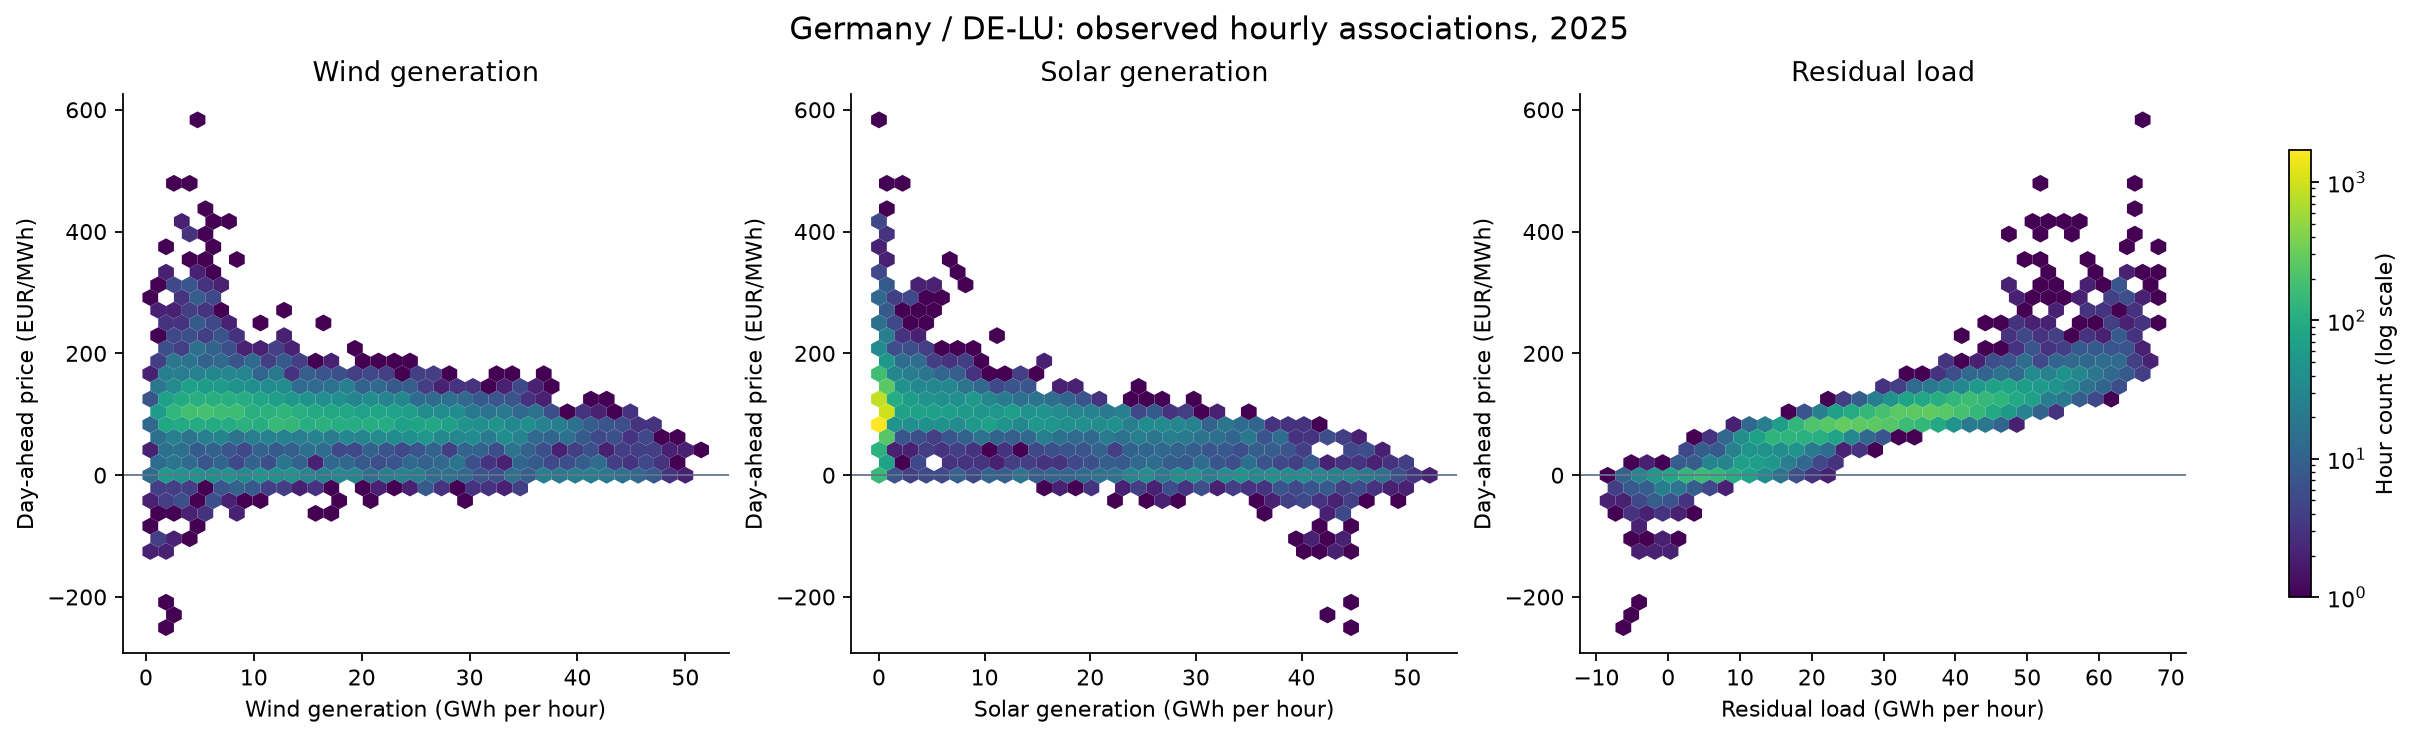

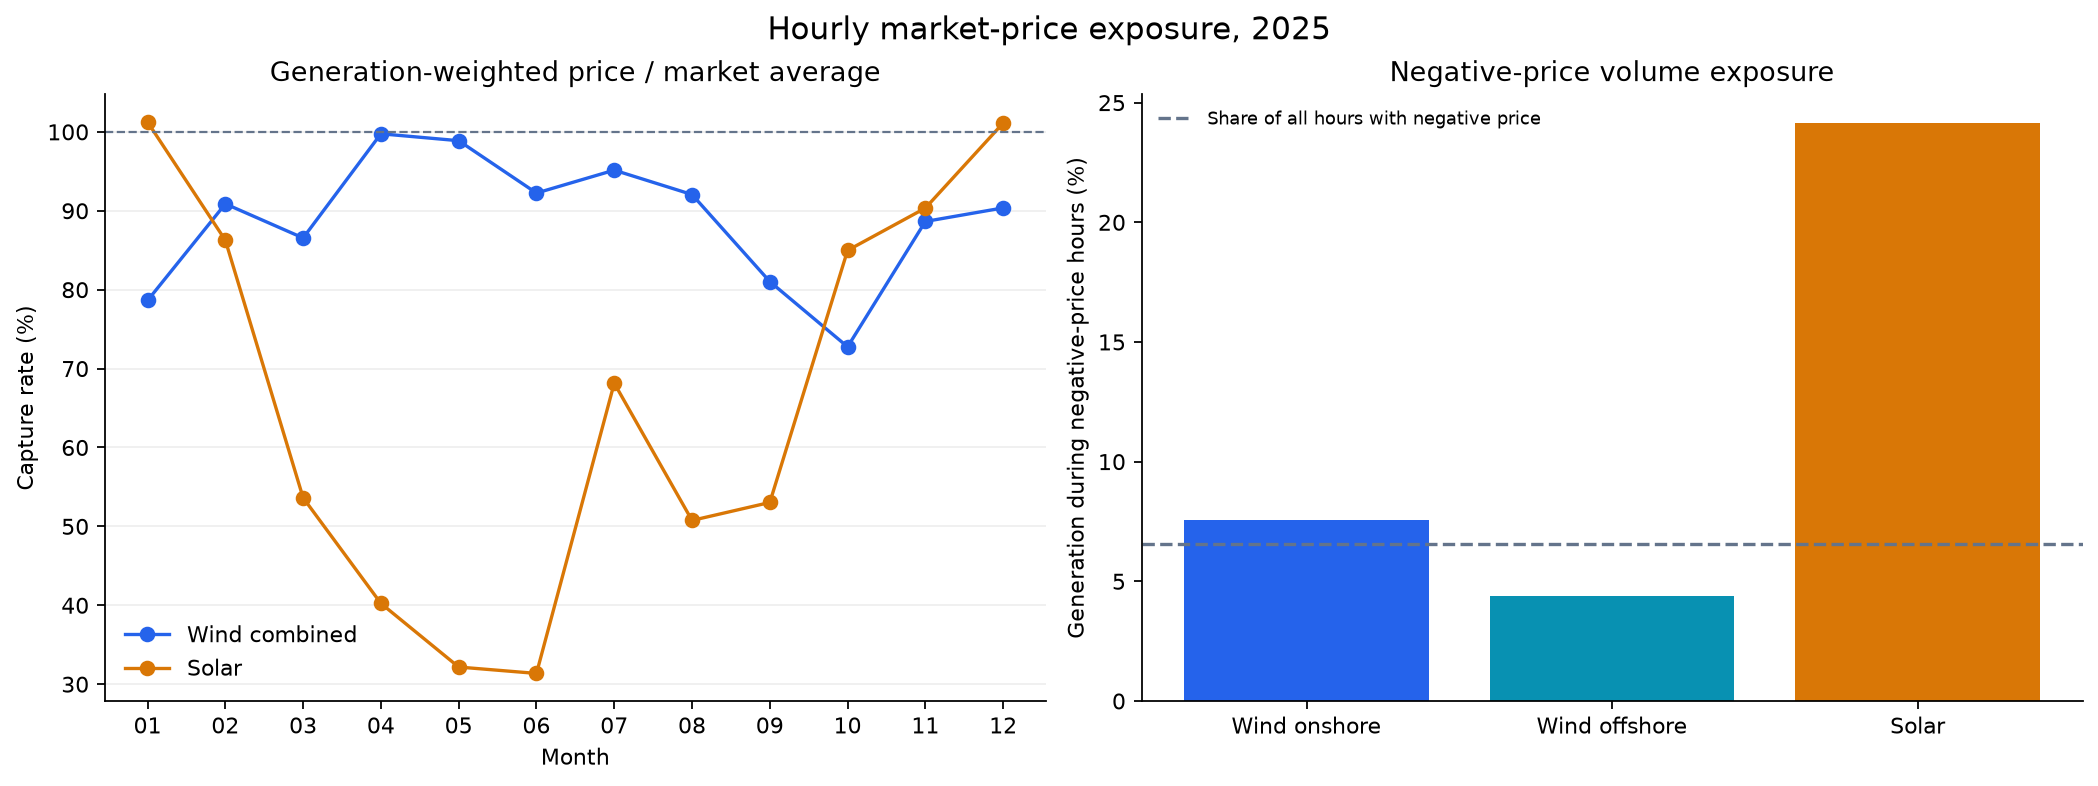

In [7]:
# EDA_ANALYSIS: association figures.
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
densities = []
for ax, variable, title in zip(axes, ["wind_mwh", "solar_mwh", "residual_load_mwh"], ["Wind generation", "Solar generation", "Residual load"]):
    density = ax.hexbin(eda_hourly[variable] / 1000, eda_hourly[price_column], gridsize=35, mincnt=1, bins="log", cmap="viridis", linewidths=0)
    densities.append(density)
    ax.axhline(0, color="#64748b", linewidth=0.8)
    ax.set_xlabel(f"{title} (GWh per hour)")
    ax.set_ylabel("Day-ahead price (EUR/MWh)")
    ax.set_title(title)
maximum_density = max(item.get_array().max() for item in densities)
for density in densities:
    density.set_norm(LogNorm(vmin=1, vmax=maximum_density))
fig.colorbar(density, ax=axes, label="Hour count (log scale)", shrink=0.8)
fig.suptitle("Germany / DE-LU: observed hourly associations, 2025", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for source, label, color in [("wind_combined", "Wind combined", "#2563eb"), ("solar", "Solar", "#d97706")]:
    group = monthly_capture.loc[monthly_capture.generation_source == source]
    axes[0].plot(group.month.str[-2:], group.capture_rate * 100, marker="o", label=label, color=color)
axes[0].axhline(100, color="#64748b", linestyle="--", linewidth=1)
axes[0].set(xlabel="Month", ylabel="Capture rate (%)", title="Generation-weighted price / market average")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.2)
selected = annual_capture.set_index("generation_source").loc[["wind_onshore", "wind_offshore", "solar"]]
axes[1].bar(["Wind onshore", "Wind offshore", "Solar"], selected.negative_price_generation_share * 100, color=["#2563eb", "#0891b2", "#d97706"])
axes[1].axhline(annual_summary.negative_price_hour_share.iloc[0] * 100, color="#64748b", linestyle="--", label="Share of all hours with negative price")
axes[1].set(ylabel="Generation during negative-price hours (%)", title="Negative-price volume exposure")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Hourly market-price exposure, 2025", fontsize=14)
plt.show()


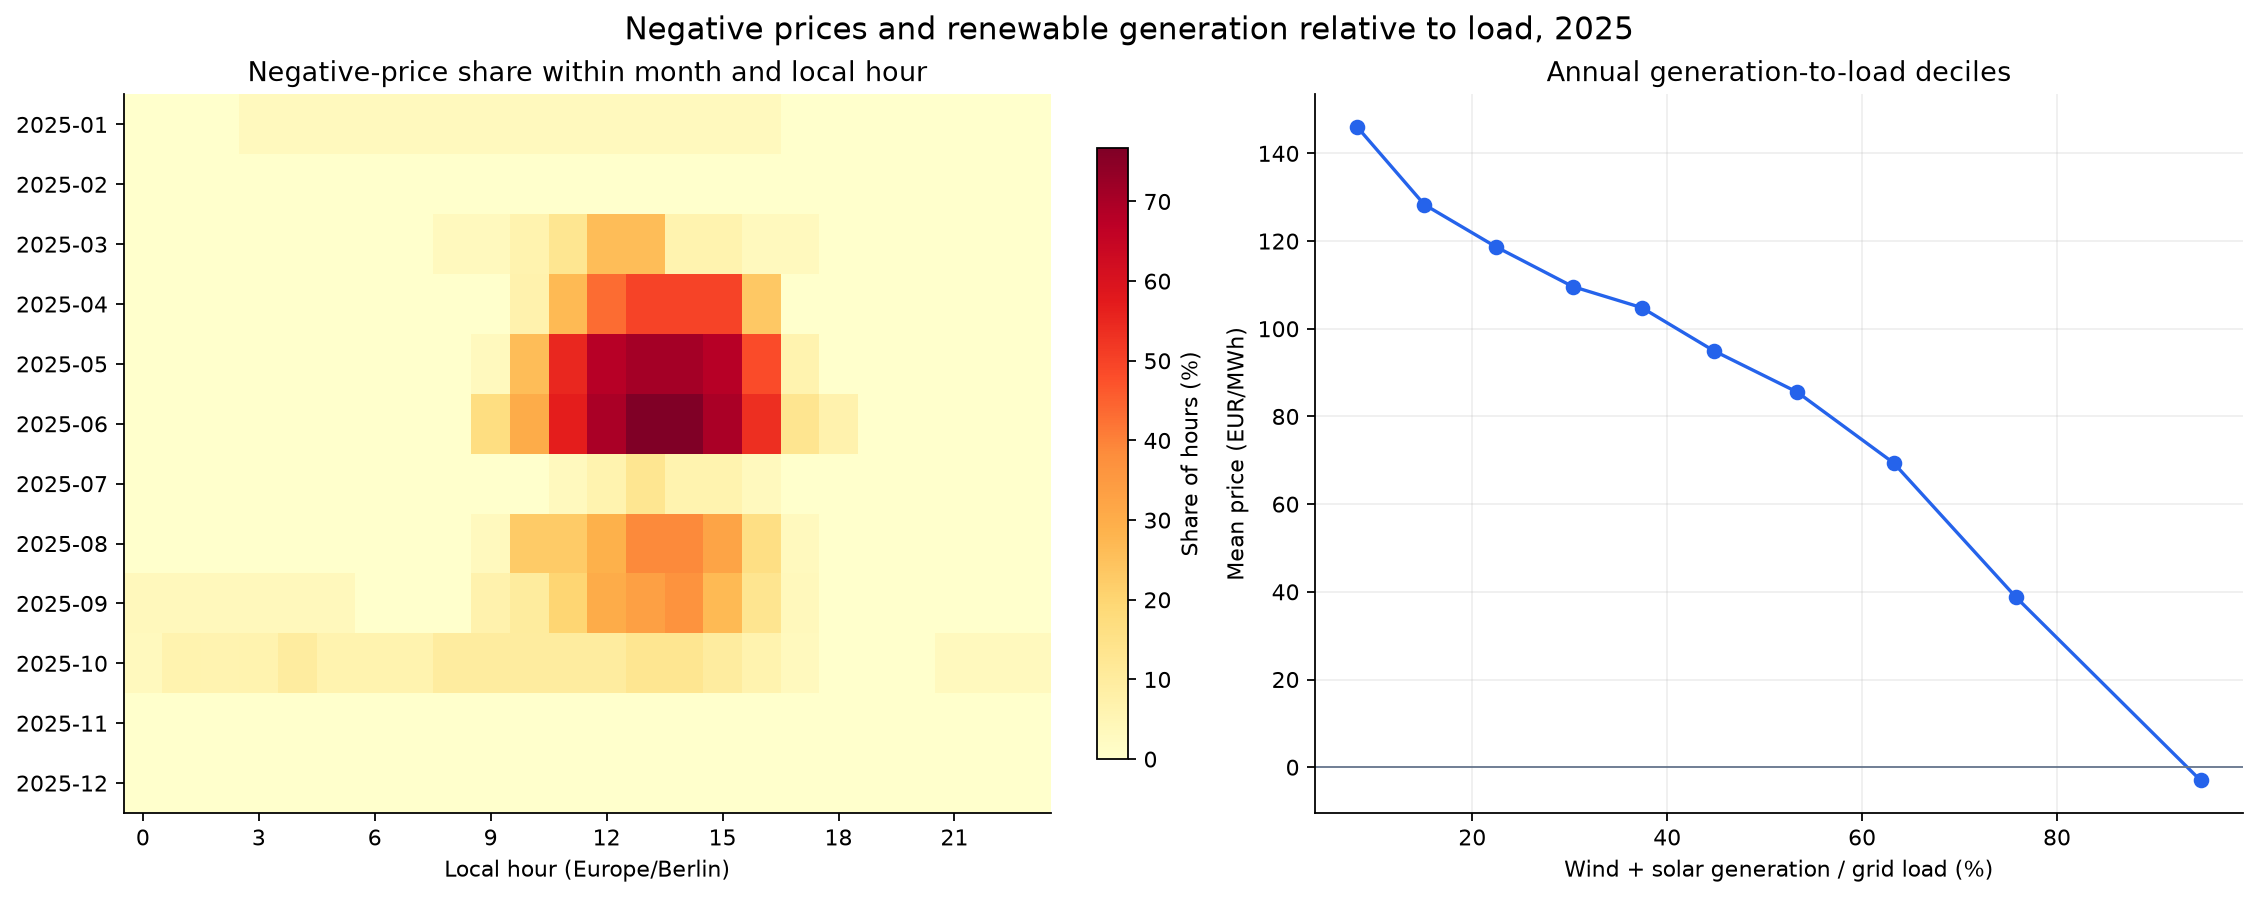

In [8]:
# EDA_ANALYSIS: calendar and regime figures.
negative_heatmap = eda_hourly.pivot_table(index="month", columns="local_hour", values="is_negative_price", aggfunc="mean") * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
image = axes[0].imshow(negative_heatmap.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0)
axes[0].set_xticks(range(0, 24, 3), range(0, 24, 3))
axes[0].set_yticks(range(12), negative_heatmap.index)
axes[0].set(xlabel="Local hour (Europe/Berlin)", title="Negative-price share within month and local hour")
fig.colorbar(image, ax=axes[0], label="Share of hours (%)", shrink=0.85)
regimes = price_regimes.loc[price_regimes.variable == "wind_solar_load_ratio"]
axes[1].plot(regimes.mean_explanatory_value * 100, regimes.average_price_eur_mwh, marker="o", color="#2563eb")
axes[1].axhline(0, color="#64748b", linewidth=0.8)
axes[1].set(xlabel="Wind + solar generation / grid load (%)", ylabel="Mean price (EUR/MWh)", title="Annual generation-to-load deciles")
axes[1].grid(alpha=0.2)
fig.suptitle("Negative prices and renewable generation relative to load, 2025", fontsize=14)
plt.show()


## Full generation mix: context beyond wind and solar

This fifth figure includes every reported generation category, not only variable renewables. Values are annual energy delivered to the public grid. The mix is not a decomposition of the electricity price or the origin of consumed electricity.

Nuclear observations remain unavailable; they are retained in the table and omitted from the bars rather than plotted as measured zero. Pumped-storage output is shown separately from renewable generation. The denominator of each share is the sum of all available generation categories, including pumped-storage output.


,generation_source,classification,valid_hours,generation_twh,share_of_reported_generation
0,Wind onshore,renewable,8760,106.7679,0.2438
1,Photovoltaics,renewable,8760,73.7838,0.1685
2,Lignite,other_generation,8760,67.1664,0.1534
3,Fossil gas,other_generation,8760,60.5474,0.1383
4,Biomass,renewable,8760,35.8741,0.0819
5,Hard coal,other_generation,8760,28.1574,0.0643
6,Wind offshore,renewable,8760,26.1946,0.0598
7,Other conventional,other_generation,8760,14.3741,0.0328
8,Hydropower,renewable,8760,14.1829,0.0324
9,Hydro pumped storage,storage_output,8760,9.8935,0.0226


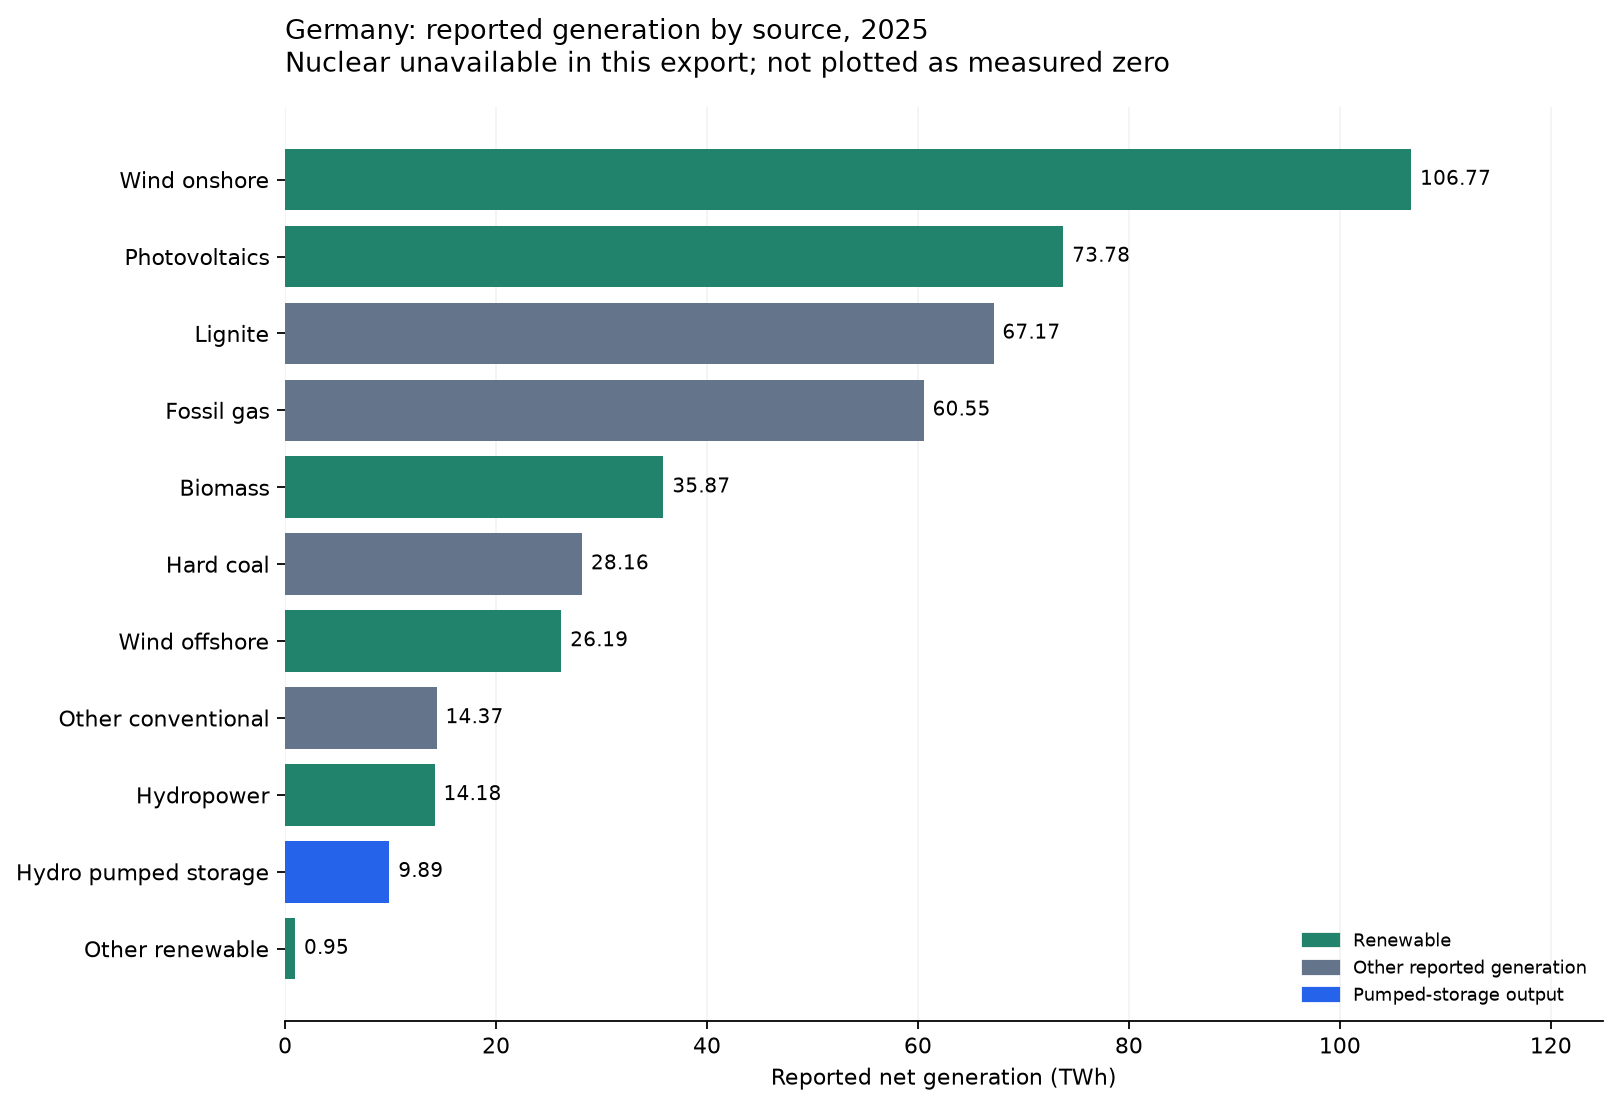

In [9]:
# EDA_ANALYSIS: full generation mix table and figure.
from matplotlib.patches import Patch

mix_sources = {
    "biomass": ("Biomass", "renewable"),
    "hydropower": ("Hydropower", "renewable"),
    "wind_offshore": ("Wind offshore", "renewable"),
    "wind_onshore": ("Wind onshore", "renewable"),
    "solar": ("Photovoltaics", "renewable"),
    "other_renewable": ("Other renewable", "renewable"),
    "nuclear": ("Nuclear", "other_generation"),
    "lignite": ("Lignite", "other_generation"),
    "hard_coal": ("Hard coal", "other_generation"),
    "fossil_gas": ("Fossil gas", "other_generation"),
    "pumped_storage": ("Hydro pumped storage", "storage_output"),
    "other_conventional": ("Other conventional", "other_generation"),
}
assert eda_generation_mix.generation_source_code.is_unique, "Duplicate generation mix categories"
assert set(eda_generation_mix.generation_source_code) == set(mix_sources), "Unexpected generation mix categories"
assert eda_generation_mix.matched_hours.eq(8760).all(), "Incomplete annual source coverage"
expected_valid = eda_generation_mix.generation_source_code.map(lambda code: 0 if code == "nuclear" else 8760)
assert eda_generation_mix.valid_hours.eq(expected_valid).all(), "Unexpected generation availability"

generation_mix = eda_generation_mix.copy()
generation_mix["generation_twh"] = pd.to_numeric(generation_mix.generation_twh, errors="raise").astype(float)
generation_mix["generation_source"] = generation_mix.generation_source_code.map(lambda code: mix_sources[code][0])
generation_mix["classification"] = generation_mix.generation_source_code.map(lambda code: mix_sources[code][1])
assert generation_mix.loc[generation_mix.generation_source_code == "nuclear", "generation_twh"].isna().all(), "Nuclear must remain unavailable"
assert generation_mix.loc[generation_mix.generation_source_code != "nuclear", "generation_twh"].notna().all(), "Missing observed source total"
reported_total = generation_mix.generation_twh.sum(min_count=1)
assert reported_total > 0, "Non-positive reported generation total"
generation_mix["share_of_reported_generation"] = generation_mix.generation_twh / reported_total
assert abs(generation_mix.share_of_reported_generation.sum() - 1) < 1e-10, "Generation shares do not reconcile"
assert abs(reported_total - eda_hourly.reported_generation_mwh.sum() / 1e6) < 1e-7, "Generation total differs from the hourly panel"
generation_mix = generation_mix.sort_values("generation_twh", ascending=False, na_position="last").reset_index(drop=True)
display(generation_mix[["generation_source", "classification", "valid_hours", "generation_twh", "share_of_reported_generation"]].round(4))

mix_plot = generation_mix.dropna(subset=["generation_twh"]).sort_values("generation_twh")
mix_colors = {"renewable": "#22836c", "storage_output": "#2563eb", "other_generation": "#64748b"}
fig, ax = plt.subplots(figsize=(10, 6.8), constrained_layout=True)
bars = ax.barh(mix_plot.generation_source, mix_plot.generation_twh, color=mix_plot.classification.map(mix_colors))
ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
ax.set_xlim(0, mix_plot.generation_twh.max() * 1.17)
ax.set_xlabel("Reported net generation (TWh)")
ax.set_title("Germany: reported generation by source, 2025\nNuclear unavailable in this export; not plotted as measured zero", loc="left", pad=16)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=mix_colors[key], label=label) for key, label in [
    ("renewable", "Renewable"), ("other_generation", "Other reported generation"), ("storage_output", "Pumped-storage output")
]], loc="lower right", frameon=False, fontsize=8)
plt.show()


## Findings and gold candidates

The local execution against the original CSV exports gives a market average of 89.32 EUR/MWh and a load-weighted price of 92.42 EUR/MWh. Annual capture prices are 46.07 for solar, 77.31 for onshore wind and 85.53 for offshore wind. Solar capture rate is 51.58%; 24.13% of solar generation occurs in negative-price hours.

There are 573 negative hourly exported prices, or 6.54% of the year. June has 141 negative hours. Its solar capture rate is 31.36%, with 46.94% of solar generation in negative-price hours. These describe market exposure, not generator profits or household bills.

Raw price correlation is 0.876 with residual load, -0.286 with wind and -0.557 with solar. After calendar adjustment, the respective values are 0.774, -0.628 and -0.232. These are descriptive relationships; actual generation is known after the day-ahead auction and cannot be treated as an available bidding-time forecast.

The gold model contains an hourly market fact and a generation-source fact with shared time, market and generation-source dimensions. The project author confirmed that notebook 04 published all five tables successfully in Fabric. Weighted prices, capture rates and exposure shares are recomputed from hourly components. Monthly means, regression coefficients and decile bins are not permanent fact tables.

The expanded EDA passed in Fabric before the generation-mix figure was added. This fifth-figure revision still awaits its Fabric run. Saved local output snapshots are labeled separately from Fabric execution evidence.
